# NLP HW3: Multi-output Learning
## Task: Semantic Relatedness & Entailment Judgment

This notebook implements a multi-task learning model using BERT for:
1. **Task 1 (Regression)**: Predicting semantic relatedness scores
2. **Task 2 (Classification)**: Predicting entailment judgments

### Dataset
- **SemEval 2014 Task 1**: Sentence pairs with relatedness scores and entailment labels
- **Splits**: Train, Validation, Test

### Model Architecture
- Base: BERT (bert-base-uncased)
- Two task-specific heads (regression + classification)
- Shared BERT encoder for both tasks

In [55]:
import os
from transformers import BertTokenizer, BertModel
from datasets import load_dataset
from evaluate import load
import torch
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from tqdm import tqdm
import numpy as np
import random

# Set random seeds for reproducibility
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"Available GPU memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Using device: cuda
CUDA device: NVIDIA RTX PRO 6000 Blackwell Server Edition
Available GPU memory: 101.97 GB


In [56]:
# Some Chinese punctuations will be tokenized as [UNK], so we replace them with English ones
token_replacement = [
    ["：" , ":"],
    ["，" , ","],
    ["“" , "\""],
    ["”" , "\""],
    ["？" , "?"],
    ["……" , "..."],
    ["！" , "!"]
]

In [57]:

tokenizer = BertTokenizer.from_pretrained("google-bert/bert-base-uncased", cache_dir="./cache/")

In [58]:
class SemevalDataset(Dataset):
    def __init__(self, split="train") -> None:
        super().__init__()
        assert split in ["train", "validation", "test"]
        # Load dataset using the Parquet export instead of script
        self.data = load_dataset(
            "sem_eval_2014_task_1", split=split, cache_dir="./cache/", revision="refs/convert/parquet"
        ).to_list()

    def __getitem__(self, index):
        d = self.data[index]
        # Replace Chinese punctuations with English ones
        for k in ["premise", "hypothesis"]:
            for tok in token_replacement:
                d[k] = d[k].replace(tok[0], tok[1])
        return d

    def __len__(self):
        return len(self.data)

data_sample = SemevalDataset(split="train").data[:3]
print(f"Dataset example: \n{data_sample[0]} \n{data_sample[1]} \n{data_sample[2]}")

Dataset example: 
{'sentence_pair_id': 1, 'premise': 'A group of kids is playing in a yard and an old man is standing in the background', 'hypothesis': 'A group of boys in a yard is playing and a man is standing in the background', 'relatedness_score': 4.5, 'entailment_judgment': 0} 
{'sentence_pair_id': 2, 'premise': 'A group of children is playing in the house and there is no man standing in the background', 'hypothesis': 'A group of kids is playing in a yard and an old man is standing in the background', 'relatedness_score': 3.200000047683716, 'entailment_judgment': 0} 
{'sentence_pair_id': 3, 'premise': 'The young boys are playing outdoors and the man is smiling nearby', 'hypothesis': 'The kids are playing outdoors near a man with a smile', 'relatedness_score': 4.699999809265137, 'entailment_judgment': 1}


In [59]:
# Define the hyperparameters
# You can modify these values if needed
lr = 3e-5
epochs = 10
train_batch_size = 8
validation_batch_size = 8
test_batch_size = 8

In [60]:
# TODO1: Create batched data for DataLoader
# `collate_fn` is a function that defines how the data batch should be packed.
# This function will be called in the DataLoader to pack the data batch.

def collate_fn(batch):
    # TODO1-1: Implement the collate_fn function
    # Extract premises and hypotheses from the batch
    premises = [item['premise'] for item in batch]
    hypotheses = [item['hypothesis'] for item in batch]
    relatedness_scores = torch.tensor([item['relatedness_score'] for item in batch], dtype=torch.float32)
    entailment_judgments = torch.tensor([item['entailment_judgment'] for item in batch], dtype=torch.long)
    
    # Ensure entailment judgments are in valid range [0, 1]
    entailment_judgments = torch.clamp(entailment_judgments, 0, 1)
    
    # Tokenize premise and hypothesis pairs
    encoded = tokenizer(
        premises, 
        hypotheses, 
        padding=True, 
        truncation=True, 
        return_tensors='pt',
        max_length=128
    )
    
    return {
        'input_ids': encoded['input_ids'],
        'attention_mask': encoded['attention_mask'],
        'token_type_ids': encoded['token_type_ids'],
        'relatedness_score': relatedness_scores,
        'entailment_judgment': entailment_judgments
    }

# TODO1-2: Define your DataLoader
dl_train = DataLoader(
    SemevalDataset(split="train"), 
    batch_size=train_batch_size, 
    shuffle=True, 
    collate_fn=collate_fn
)
dl_validation = DataLoader(
    SemevalDataset(split="validation"), 
    batch_size=validation_batch_size, 
    shuffle=False, 
    collate_fn=collate_fn
)
dl_test = DataLoader(
    SemevalDataset(split="test"), 
    batch_size=test_batch_size, 
    shuffle=False, 
    collate_fn=collate_fn
)

print(f"Train batches: {len(dl_train)}, Validation batches: {len(dl_validation)}, Test batches: {len(dl_test)}")

Train batches: 563, Validation batches: 63, Test batches: 616


In [61]:
# TODO2: Construct your model
class MultiLabelModel(torch.nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Load BERT base model
        self.bert = BertModel.from_pretrained("google-bert/bert-base-uncased", cache_dir="./cache/")
        
        # Get hidden size from BERT config (768 for bert-base)
        hidden_size = self.bert.config.hidden_size
        
        # Task 1: Regression head for relatedness score (continuous value)
        self.regression_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 1)
        )
        
        # Task 2: Classification head for entailment judgment (binary classification)
        self.classification_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 2)  # 2 classes: 0 or 1
        )
    
    def forward(self, input_ids, attention_mask, token_type_ids, **kwargs):
        # Forward pass through BERT
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        # Use [CLS] token representation (first token)
        cls_output = outputs.last_hidden_state[:, 0, :]  # Shape: (batch_size, hidden_size)
        
        # Task 1: Regression for relatedness score
        relatedness_pred = self.regression_head(cls_output).squeeze(-1)  # Shape: (batch_size,)
        
        # Task 2: Classification for entailment judgment
        entailment_logits = self.classification_head(cls_output)  # Shape: (batch_size, 2)
        
        return {
            'relatedness_pred': relatedness_pred,
            'entailment_logits': entailment_logits
        }

In [62]:
# TODO3: Define your optimizer and loss function

model = MultiLabelModel().to(device)

# Print model parameter count
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")

# TODO3-1: Define your Optimizer
optimizer = AdamW(model.parameters(), lr=lr, weight_decay=0.01)

# TODO3-2: Define your loss functions (you should have two)
# Loss function for regression task (relatedness score)
regression_loss_fn = torch.nn.MSELoss()

# Loss function for classification task (entailment judgment)
classification_loss_fn = torch.nn.CrossEntropyLoss()

# scoring functions
psr = load("pearsonr")
acc = load("accuracy")

Total parameters: 109,876,739
Trainable parameters: 109,876,739


In [63]:
# Create saved_models directory if it doesn't exist
os.makedirs('./saved_models', exist_ok=True)

best_score = 0.0
training_history = {
    'train_loss': [],
    'val_pearson': [],
    'val_accuracy': []
}

for ep in range(epochs):
    pbar = tqdm(dl_train)
    pbar.set_description(f"Training epoch [{ep+1}/{epochs}]")
    model.train()
    # TODO4: Write the training loop
    total_train_loss = 0
    for batch in pbar:
        # Clear gradient
        optimizer.zero_grad()
        
        # Move batch to device
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        # Compute loss for both tasks
        regression_loss = regression_loss_fn(outputs['relatedness_pred'], relatedness_score)
        classification_loss = classification_loss_fn(outputs['entailment_logits'], entailment_judgment)
        
        # Combined loss
        loss = regression_loss + classification_loss
        
        # Back-propagation
        loss.backward()
        
        # Gradient clipping to prevent exploding gradients
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        
        # Model optimization
        optimizer.step()
        
        total_train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = total_train_loss / len(dl_train)
    training_history['train_loss'].append(avg_train_loss)
    print(f"Epoch {ep+1}/{epochs} - Average Training Loss: {avg_train_loss:.4f}")

    pbar = tqdm(dl_validation)
    pbar.set_description(f"Validation epoch [{ep+1}/{epochs}]")
    model.eval()
    # TODO5: Write the evaluation loop
    all_relatedness_preds = []
    all_relatedness_targets = []
    all_entailment_preds = []
    all_entailment_targets = []
    
    with torch.no_grad():
        for batch in pbar:
            # Move batch to device
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            token_type_ids = batch['token_type_ids'].to(device)
            relatedness_score = batch['relatedness_score'].to(device)
            entailment_judgment = batch['entailment_judgment'].to(device)
            
            # Forward pass
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids
            )
            
            # Collect predictions and targets for regression task
            all_relatedness_preds.extend(outputs['relatedness_pred'].cpu().numpy().tolist())
            all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
            
            # Collect predictions and targets for classification task
            entailment_pred_labels = torch.argmax(outputs['entailment_logits'], dim=1)
            all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
            all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())
    
    # Evaluate your model
    # Output all the evaluation scores (PearsonCorr, Accuracy)
    pearson_corr = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
    accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']
    
    training_history['val_pearson'].append(pearson_corr)
    training_history['val_accuracy'].append(accuracy)
    
    print(f"Epoch {ep+1}/{epochs} - Validation Pearson Correlation: {pearson_corr:.4f}, Accuracy: {accuracy:.4f}")
    
    # Save best model based on combined score
    combined_score = pearson_corr + accuracy
    if combined_score > best_score:
        best_score = combined_score
        torch.save(model.state_dict(), f'./saved_models/best_model.ckpt')
        print(f"✓ New best model saved with combined score: {best_score:.4f}")

print("\n" + "="*50)
print("Training Summary")
print("="*50)
for ep in range(epochs):
    print(f"Epoch {ep+1}: Train Loss={training_history['train_loss'][ep]:.4f}, "
          f"Val Pearson={training_history['val_pearson'][ep]:.4f}, "
          f"Val Accuracy={training_history['val_accuracy'][ep]:.4f}")
print("="*50)

Training epoch [1/10]:   0%|          | 0/563 [00:00<?, ?it/s]

Training epoch [1/10]: 100%|██████████| 563/563 [00:26<00:00, 21.58it/s, loss=0.9049]


Epoch 1/10 - Average Training Loss: 1.0326


Validation epoch [1/10]: 100%|██████████| 63/63 [00:00<00:00, 85.74it/s]



Epoch 1/10 - Validation Pearson Correlation: 0.8673, Accuracy: 0.8580
✓ New best model saved with combined score: 1.7253
✓ New best model saved with combined score: 1.7253


...

Epoch 9/10 - Validation Pearson Correlation: 0.8622, Accuracy: 0.8700


Training epoch [10/10]: 100%|██████████| 563/563 [00:24<00:00, 23.25it/s, loss=0.0762]


Epoch 10/10 - Average Training Loss: 0.1411


Validation epoch [10/10]: 100%|██████████| 63/63 [00:00<00:00, 86.06it/s]



Epoch 10/10 - Validation Pearson Correlation: 0.8784, Accuracy: 0.8860
✓ New best model saved with combined score: 1.7644

Training Summary
Epoch 1: Train Loss=1.0326, Val Pearson=0.8673, Val Accuracy=0.8580
Epoch 2: Train Loss=0.5353, Val Pearson=0.8650, Val Accuracy=0.8380
Epoch 3: Train Loss=0.3941, Val Pearson=0.8622, Val Accuracy=0.8440
Epoch 4: Train Loss=0.3148, Val Pearson=0.8547, Val Accuracy=0.8580
Epoch 5: Train Loss=0.2656, Val Pearson=0.8768, Val Accuracy=0.8580
Epoch 6: Train Loss=0.2150, Val Pearson=0.8759, Val Accuracy=0.8520
Epoch 7: Train Loss=0.1911, Val Pearson=0.8605, Val Accuracy=0.8480
Epoch 8: Train Loss=0.1712, Val Pearson=0.8681, Val Accuracy=0.8600
Epoch 9: Train Loss=0.1529, Val Pearson=0.8622, Val Accuracy=0.8700
Epoch 10: Train Loss=0.1411, Val Pearson=0.8784, Val Accuracy=0.8860
✓ New best model saved with combined score: 1.7644

Training Summary
Epoch 1: Train Loss=1.0326, Val Pearson=0.8673, Val Accuracy=0.8580
Epoch 2: Train Loss=0.5353, Val Pearson=0.

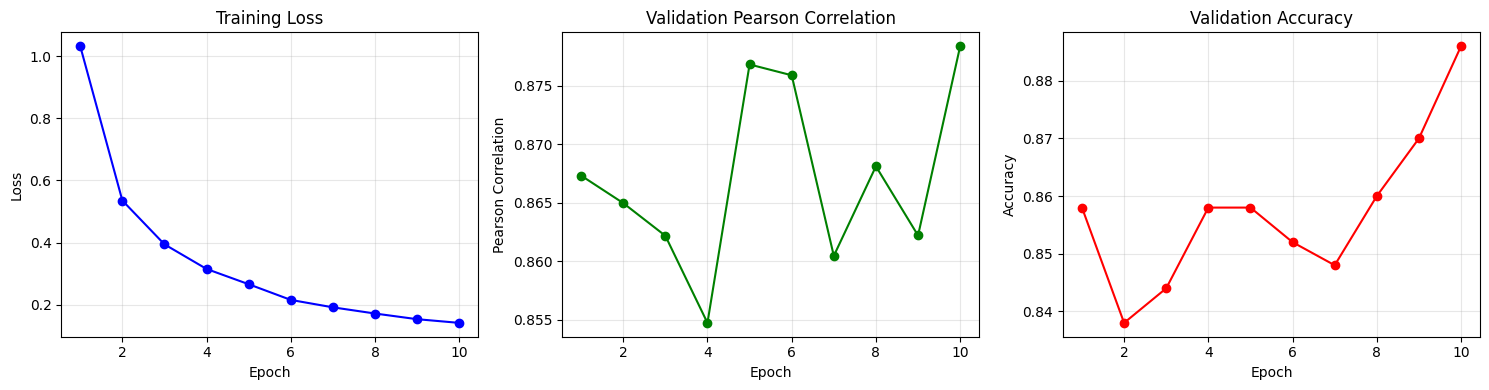

In [64]:
# Optional: Visualize training history
try:
    import matplotlib.pyplot as plt
    
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    
    # Plot training loss
    axes[0].plot(range(1, epochs+1), training_history['train_loss'], marker='o', color='blue')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Loss')
    axes[0].set_title('Training Loss')
    axes[0].grid(True, alpha=0.3)
    
    # Plot validation Pearson correlation
    axes[1].plot(range(1, epochs+1), training_history['val_pearson'], marker='o', color='green')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Pearson Correlation')
    axes[1].set_title('Validation Pearson Correlation')
    axes[1].grid(True, alpha=0.3)
    
    # Plot validation accuracy
    axes[2].plot(range(1, epochs+1), training_history['val_accuracy'], marker='o', color='red')
    axes[2].set_xlabel('Epoch')
    axes[2].set_ylabel('Accuracy')
    axes[2].set_title('Validation Accuracy')
    axes[2].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()
except ImportError:
    print("Matplotlib not installed. Install with: pip install matplotlib")

In [65]:
# Load the model
model = MultiLabelModel().to(device)
model.load_state_dict(torch.load(f"./saved_models/best_model.ckpt", weights_only=True))

# Test Loop
pbar = tqdm(dl_test, desc="Test")
model.eval()

# TODO6: Write the test loop
all_relatedness_preds = []
all_relatedness_targets = []
all_entailment_preds = []
all_entailment_targets = []

with torch.no_grad():
    for batch in pbar:
        # Move batch to device
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        # Forward pass
        outputs = model(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        # Collect predictions and targets for regression task
        all_relatedness_preds.extend(outputs['relatedness_pred'].cpu().numpy().tolist())
        all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
        
        # Collect predictions and targets for classification task
        entailment_pred_labels = torch.argmax(outputs['entailment_logits'], dim=1)
        all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
        all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())

# Compute test metrics
test_pearson_corr = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
test_accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']

print(f"\n{'='*50}")
print(f"Test Results:")
print(f"{'='*50}")
print(f"Pearson Correlation: {test_pearson_corr:.4f}")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Combined Score: {test_pearson_corr + test_accuracy:.4f}")
print(f"{'='*50}")

Test: 100%|██████████| 616/616 [00:05<00:00, 110.43it/s]


Test Results:
Pearson Correlation: 0.8881
Accuracy: 0.8811
Combined Score: 1.7691


## Part 2: RoBERTa-base Model Training

Now let's train a RoBERTa-base model on the same dataset for comparison.

In [66]:
# Import RoBERTa components
from transformers import RobertaTokenizer, RobertaModel

# Initialize RoBERTa tokenizer
roberta_tokenizer = RobertaTokenizer.from_pretrained("roberta-base", cache_dir="./cache/")
print("RoBERTa tokenizer loaded successfully")

RoBERTa tokenizer loaded successfully


In [67]:
# Define RoBERTa multi-task model
class MultiLabelModelRoBERTa(torch.nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Load RoBERTa base model
        self.roberta = RobertaModel.from_pretrained("roberta-base", cache_dir="./cache/")
        
        # Get hidden size from RoBERTa config (768 for roberta-base)
        hidden_size = self.roberta.config.hidden_size
        
        # Task 1: Regression head for relatedness score
        self.regression_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 1)
        )
        
        # Task 2: Classification head for entailment judgment
        self.classification_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 2)
        )
    
    def forward(self, input_ids, attention_mask, **kwargs):
        # RoBERTa doesn't use token_type_ids
        outputs = self.roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        
        # Use [CLS] token representation (first token)
        cls_output = outputs.last_hidden_state[:, 0, :]
        
        # Task 1: Regression for relatedness score
        relatedness_pred = self.regression_head(cls_output).squeeze(-1)
        
        # Task 2: Classification for entailment judgment
        entailment_logits = self.classification_head(cls_output)
        
        return {
            'relatedness_pred': relatedness_pred,
            'entailment_logits': entailment_logits
        }

print("RoBERTa model class defined successfully")

RoBERTa model class defined successfully


In [68]:
# Create collate_fn for RoBERTa
def collate_fn_roberta(batch):
    # Extract premises and hypotheses from the batch
    premises = [item['premise'] for item in batch]
    hypotheses = [item['hypothesis'] for item in batch]
    relatedness_scores = torch.tensor([item['relatedness_score'] for item in batch], dtype=torch.float32)
    entailment_judgments = torch.tensor([item['entailment_judgment'] for item in batch], dtype=torch.long)
    
    # Ensure entailment judgments are in valid range [0, 1]
    entailment_judgments = torch.clamp(entailment_judgments, 0, 1)
    
    # Tokenize with RoBERTa tokenizer (no token_type_ids)
    encoded = roberta_tokenizer(
        premises, 
        hypotheses, 
        padding=True, 
        truncation=True, 
        return_tensors='pt',
        max_length=128
    )
    
    return {
        'input_ids': encoded['input_ids'],
        'attention_mask': encoded['attention_mask'],
        'relatedness_score': relatedness_scores,
        'entailment_judgment': entailment_judgments
    }

# Create DataLoaders for RoBERTa
dl_train_roberta = DataLoader(
    SemevalDataset(split="train"), 
    batch_size=train_batch_size, 
    shuffle=True, 
    collate_fn=collate_fn_roberta
)
dl_validation_roberta = DataLoader(
    SemevalDataset(split="validation"), 
    batch_size=validation_batch_size, 
    shuffle=False, 
    collate_fn=collate_fn_roberta
)
dl_test_roberta = DataLoader(
    SemevalDataset(split="test"), 
    batch_size=test_batch_size, 
    shuffle=False, 
    collate_fn=collate_fn_roberta
)

print(f"RoBERTa DataLoaders created - Train: {len(dl_train_roberta)}, Val: {len(dl_validation_roberta)}, Test: {len(dl_test_roberta)}")

RoBERTa DataLoaders created - Train: 563, Val: 63, Test: 616


In [69]:
# Train RoBERTa model
model_roberta = MultiLabelModelRoBERTa().to(device)

total_params_roberta = sum(p.numel() for p in model_roberta.parameters())
trainable_params_roberta = sum(p.numel() for p in model_roberta.parameters() if p.requires_grad)
print(f"RoBERTa - Total parameters: {total_params_roberta:,}, Trainable: {trainable_params_roberta:,}")

# Optimizer for RoBERTa
optimizer_roberta = AdamW(model_roberta.parameters(), lr=lr, weight_decay=0.01)

best_score_roberta = 0.0
training_history_roberta = {
    'train_loss': [],
    'val_pearson': [],
    'val_accuracy': []
}

for ep in range(epochs):
    pbar = tqdm(dl_train_roberta)
    pbar.set_description(f"[RoBERTa] Training epoch [{ep+1}/{epochs}]")
    model_roberta.train()
    total_train_loss = 0
    
    for batch in pbar:
        optimizer_roberta.zero_grad()
        
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        # Forward pass (RoBERTa doesn't need token_type_ids)
        outputs = model_roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        
        # Compute loss for both tasks
        regression_loss = regression_loss_fn(outputs['relatedness_pred'], relatedness_score)
        classification_loss = classification_loss_fn(outputs['entailment_logits'], entailment_judgment)
        
        # Combined loss
        loss = regression_loss + classification_loss
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_roberta.parameters(), max_norm=1.0)
        optimizer_roberta.step()
        
        total_train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = total_train_loss / len(dl_train_roberta)
    training_history_roberta['train_loss'].append(avg_train_loss)
    print(f"[RoBERTa] Epoch {ep+1}/{epochs} - Average Training Loss: {avg_train_loss:.4f}")

    pbar = tqdm(dl_validation_roberta)
    pbar.set_description(f"[RoBERTa] Validation epoch [{ep+1}/{epochs}]")
    model_roberta.eval()
    all_relatedness_preds = []
    all_relatedness_targets = []
    all_entailment_preds = []
    all_entailment_targets = []
    
    with torch.no_grad():
        for batch in pbar:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            relatedness_score = batch['relatedness_score'].to(device)
            entailment_judgment = batch['entailment_judgment'].to(device)
            
            outputs = model_roberta(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            
            all_relatedness_preds.extend(outputs['relatedness_pred'].cpu().numpy().tolist())
            all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
            
            entailment_pred_labels = torch.argmax(outputs['entailment_logits'], dim=1)
            all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
            all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())
    
    pearson_corr = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
    accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']
    
    training_history_roberta['val_pearson'].append(pearson_corr)
    training_history_roberta['val_accuracy'].append(accuracy)
    
    print(f"[RoBERTa] Epoch {ep+1}/{epochs} - Validation Pearson: {pearson_corr:.4f}, Accuracy: {accuracy:.4f}")
    
    combined_score = pearson_corr + accuracy
    if combined_score > best_score_roberta:
        best_score_roberta = combined_score
        torch.save(model_roberta.state_dict(), './saved_models/best_model_roberta.ckpt')
        print(f"✓ [RoBERTa] New best model saved with combined score: {best_score_roberta:.4f}")

print("\n" + "="*50)
print("[RoBERTa] Training Summary")
print("="*50)
for ep in range(epochs):
    print(f"Epoch {ep+1}: Train Loss={training_history_roberta['train_loss'][ep]:.4f}, "
          f"Val Pearson={training_history_roberta['val_pearson'][ep]:.4f}, "
          f"Val Accuracy={training_history_roberta['val_accuracy'][ep]:.4f}")
print("="*50)

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-base and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


RoBERTa - Total parameters: 125,040,131, Trainable: 125,040,131


[RoBERTa] Training epoch [1/10]: 100%|██████████| 563/563 [00:25<00:00, 21.75it/s, loss=0.5101]


[RoBERTa] Epoch 1/10 - Average Training Loss: 1.2407


[RoBERTa] Validation epoch [1/10]: 100%|██████████| 63/63 [00:00<00:00, 101.32it/s]



...

[RoBERTa] Epoch 9/10 - Validation Pearson: 0.8861, Accuracy: 0.8740


[RoBERTa] Training epoch [10/10]: 100%|██████████| 563/563 [00:25<00:00, 21.97it/s, loss=0.1799]


[RoBERTa] Epoch 10/10 - Average Training Loss: 0.2387


[RoBERTa] Validation epoch [10/10]: 100%|██████████| 63/63 [00:00<00:00, 102.37it/s]


[RoBERTa] Epoch 10/10 - Validation Pearson: 0.8898, Accuracy: 0.8800

[RoBERTa] Training Summary
Epoch 1: Train Loss=1.2407, Val Pearson=0.8550, Val Accuracy=0.8620
Epoch 2: Train Loss=0.6433, Val Pearson=0.8694, Val Accuracy=0.8740
Epoch 3: Train Loss=0.5174, Val Pearson=0.8719, Val Accuracy=0.8640
Epoch 4: Train Loss=0.4563, Val Pearson=0.8726, Val Accuracy=0.8860
Epoch 5: Train Loss=0.3825, Val Pearson=0.8946, Val Accuracy=0.8940
Epoch 6: Train Loss=0.3427, Val Pearson=0.8933, Val Accuracy=0.9000
Epoch 7: Train Loss=0.3167, Val Pearson=0.8940, Val Accuracy=0.8860
Epoch 8: Train Loss=0.2720, Val Pearson=0.8833, Val Accuracy=0.8580
Epoch 9: Train Loss=0.2579, Val Pearson=0.8861, Val Accuracy=0.8740
Epoch 10: Train Loss=0.2387, Val Pearson=0.8898, Val Accuracy=0.8800


In [70]:
# Test RoBERTa model
model_roberta.load_state_dict(torch.load("./saved_models/best_model_roberta.ckpt", weights_only=True))

pbar = tqdm(dl_test_roberta, desc="[RoBERTa] Test")
model_roberta.eval()

all_relatedness_preds = []
all_relatedness_targets = []
all_entailment_preds = []
all_entailment_targets = []

with torch.no_grad():
    for batch in pbar:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        outputs = model_roberta(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        
        all_relatedness_preds.extend(outputs['relatedness_pred'].cpu().numpy().tolist())
        all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
        
        entailment_pred_labels = torch.argmax(outputs['entailment_logits'], dim=1)
        all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
        all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())

roberta_test_pearson = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
roberta_test_accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']

print(f"\n{'='*50}")
print(f"[RoBERTa] Test Results:")
print(f"{'='*50}")
print(f"Pearson Correlation: {roberta_test_pearson:.4f}")
print(f"Accuracy: {roberta_test_accuracy:.4f}")
print(f"Combined Score: {roberta_test_pearson + roberta_test_accuracy:.4f}")
print(f"{'='*50}")

[RoBERTa] Test: 100%|██████████| 616/616 [00:04<00:00, 137.56it/s]




[RoBERTa] Test Results:
Pearson Correlation: 0.8898
Accuracy: 0.8837
Combined Score: 1.7735


## Part 3: GPT-2 Model Training

Now let's train a GPT-2 model on the same dataset for comparison.

In [71]:
# Import GPT-2 components
from transformers import GPT2Tokenizer, GPT2Model

# Initialize GPT-2 tokenizer
gpt2_tokenizer = GPT2Tokenizer.from_pretrained("gpt2", cache_dir="./cache/")
gpt2_tokenizer.pad_token = gpt2_tokenizer.eos_token
print("GPT-2 tokenizer loaded successfully")

GPT-2 tokenizer loaded successfully


In [72]:
# Define GPT-2 multi-task model
class MultiLabelModelGPT2(torch.nn.Module):
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        # Load GPT-2 base model
        self.gpt2 = GPT2Model.from_pretrained("gpt2", cache_dir="./cache/")
        
        # Get hidden size from GPT-2 config (768 for gpt2)
        hidden_size = self.gpt2.config.n_embd
        
        # Task 1: Regression head for relatedness score
        self.regression_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 1)
        )
        
        # Task 2: Classification head for entailment judgment
        self.classification_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 2)
        )
    
    def forward(self, input_ids, attention_mask, **kwargs):
        # Forward pass through GPT-2
        outputs = self.gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        
        # Use last token representation for GPT-2 (causal model)
        # Get sequence lengths from attention mask
        sequence_lengths = attention_mask.sum(dim=1) - 1
        batch_size = input_ids.shape[0]
        last_hidden_states = outputs.last_hidden_state[range(batch_size), sequence_lengths]
        
        # Task 1: Regression for relatedness score
        relatedness_pred = self.regression_head(last_hidden_states).squeeze(-1)
        
        # Task 2: Classification for entailment judgment
        entailment_logits = self.classification_head(last_hidden_states)
        
        return {
            'relatedness_pred': relatedness_pred,
            'entailment_logits': entailment_logits
        }

print("GPT-2 model class defined successfully")

GPT-2 model class defined successfully


In [73]:
# Create collate_fn for GPT-2
def collate_fn_gpt2(batch):
    premises = [item['premise'] for item in batch]
    hypotheses = [item['hypothesis'] for item in batch]
    relatedness_scores = torch.tensor([item['relatedness_score'] for item in batch], dtype=torch.float32)
    entailment_judgments = torch.tensor([item['entailment_judgment'] for item in batch], dtype=torch.long)
    
    entailment_judgments = torch.clamp(entailment_judgments, 0, 1)
    
    # Tokenize with GPT-2 tokenizer (no token_type_ids)
    encoded = gpt2_tokenizer(
        premises, 
        hypotheses, 
        padding=True, 
        truncation=True, 
        return_tensors='pt',
        max_length=128
    )
    
    return {
        'input_ids': encoded['input_ids'],
        'attention_mask': encoded['attention_mask'],
        'relatedness_score': relatedness_scores,
        'entailment_judgment': entailment_judgments
    }

# Create DataLoaders for GPT-2
dl_train_gpt2 = DataLoader(
    SemevalDataset(split="train"), 
    batch_size=train_batch_size, 
    shuffle=True, 
    collate_fn=collate_fn_gpt2
)
dl_validation_gpt2 = DataLoader(
    SemevalDataset(split="validation"), 
    batch_size=validation_batch_size, 
    shuffle=False, 
    collate_fn=collate_fn_gpt2
)
dl_test_gpt2 = DataLoader(
    SemevalDataset(split="test"), 
    batch_size=test_batch_size, 
    shuffle=False, 
    collate_fn=collate_fn_gpt2
)

print(f"GPT-2 DataLoaders created - Train: {len(dl_train_gpt2)}, Val: {len(dl_validation_gpt2)}, Test: {len(dl_test_gpt2)}")

GPT-2 DataLoaders created - Train: 563, Val: 63, Test: 616


In [74]:
# Train GPT-2 model
model_gpt2 = MultiLabelModelGPT2().to(device)

total_params_gpt2 = sum(p.numel() for p in model_gpt2.parameters())
trainable_params_gpt2 = sum(p.numel() for p in model_gpt2.parameters() if p.requires_grad)
print(f"GPT-2 - Total parameters: {total_params_gpt2:,}, Trainable: {trainable_params_gpt2:,}")

# Optimizer for GPT-2
optimizer_gpt2 = AdamW(model_gpt2.parameters(), lr=lr, weight_decay=0.01)

best_score_gpt2 = 0.0
training_history_gpt2 = {
    'train_loss': [],
    'val_pearson': [],
    'val_accuracy': []
}

for ep in range(epochs):
    pbar = tqdm(dl_train_gpt2)
    pbar.set_description(f"[GPT-2] Training epoch [{ep+1}/{epochs}]")
    model_gpt2.train()
    total_train_loss = 0
    
    for batch in pbar:
        optimizer_gpt2.zero_grad()
        
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        # Forward pass
        outputs = model_gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        
        # Compute loss for both tasks
        regression_loss = regression_loss_fn(outputs['relatedness_pred'], relatedness_score)
        classification_loss = classification_loss_fn(outputs['entailment_logits'], entailment_judgment)
        
        # Combined loss
        loss = regression_loss + classification_loss
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_gpt2.parameters(), max_norm=1.0)
        optimizer_gpt2.step()
        
        total_train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = total_train_loss / len(dl_train_gpt2)
    training_history_gpt2['train_loss'].append(avg_train_loss)
    print(f"[GPT-2] Epoch {ep+1}/{epochs} - Average Training Loss: {avg_train_loss:.4f}")

    pbar = tqdm(dl_validation_gpt2)
    pbar.set_description(f"[GPT-2] Validation epoch [{ep+1}/{epochs}]")
    model_gpt2.eval()
    all_relatedness_preds = []
    all_relatedness_targets = []
    all_entailment_preds = []
    all_entailment_targets = []
    
    with torch.no_grad():
        for batch in pbar:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            relatedness_score = batch['relatedness_score'].to(device)
            entailment_judgment = batch['entailment_judgment'].to(device)
            
            outputs = model_gpt2(
                input_ids=input_ids,
                attention_mask=attention_mask
            )
            
            all_relatedness_preds.extend(outputs['relatedness_pred'].cpu().numpy().tolist())
            all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
            
            entailment_pred_labels = torch.argmax(outputs['entailment_logits'], dim=1)
            all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
            all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())
    
    pearson_corr = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
    accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']
    
    training_history_gpt2['val_pearson'].append(pearson_corr)
    training_history_gpt2['val_accuracy'].append(accuracy)
    
    print(f"[GPT-2] Epoch {ep+1}/{epochs} - Validation Pearson: {pearson_corr:.4f}, Accuracy: {accuracy:.4f}")
    
    combined_score = pearson_corr + accuracy
    if combined_score > best_score_gpt2:
        best_score_gpt2 = combined_score
        torch.save(model_gpt2.state_dict(), './saved_models/best_model_gpt2.ckpt')
        print(f"✓ [GPT-2] New best model saved with combined score: {best_score_gpt2:.4f}")

print("\n" + "="*50)
print("[GPT-2] Training Summary")
print("="*50)
for ep in range(epochs):
    print(f"Epoch {ep+1}: Train Loss={training_history_gpt2['train_loss'][ep]:.4f}, "
          f"Val Pearson={training_history_gpt2['val_pearson'][ep]:.4f}, "
          f"Val Accuracy={training_history_gpt2['val_accuracy'][ep]:.4f}")
print("="*50)

GPT-2 - Total parameters: 124,834,307, Trainable: 124,834,307


[GPT-2] Training epoch [1/10]: 100%|██████████| 563/563 [00:24<00:00, 23.25it/s, loss=2.1318]


[GPT-2] Epoch 1/10 - Average Training Loss: 1.2794


[GPT-2] Validation epoch [1/10]: 100%|██████████| 63/63 [00:00<00:00, 140.30it/s]



[GPT-2] Epoch 1/10 - Validation Pearson: 0.8077, Accuracy: 0.8540
✓ [GPT-2] New best model saved with combined score: 1.6617
✓ [GPT-2] New best model saved with combined score: 1.6617


...

[GPT-2] Epoch 9/10 - Validation Pearson: 0.8573, Accuracy: 0.8720
✓ [GPT-2] New best model saved with combined score: 1.7293
✓ [GPT-2] New best model saved with combined score: 1.7293


[GPT-2] Training epoch [10/10]: 100%|██████████| 563/563 [00:24<00:00, 22.86it/s, loss=0.1892]


[GPT-2] Epoch 10/10 - Average Training Loss: 0.1773


[GPT-2] Validation epoch [10/10]: 100%|██████████| 63/63 [00:00<00:00, 135.85it/s]

[GPT-2] Epoch 10/10 - Validation Pearson: 0.8531, Accuracy: 0.8620

[GPT-2] Training Summary
Epoch 1: Train Loss=1.2794, Val Pearson=0.8077, Val Accuracy=0.8540
Epoch 2: Train Loss=0.7354, Val Pearson=0.8339, Val Accuracy=0.8480
Epoch 3: Train Loss=0.5440, Val Pearson=0.8499, Val Accuracy=0.8620
Epoch 4: Train Loss=0.4553, Val Pearson=0.8551, Val Accuracy=0.8700
Epoch 5: Train Loss=0.3564, Val Pearson=0.8618, Val Accuracy=0.8640
Epoch 6: Train Loss=0.3017, Val Pearson=0.8649, Val Accuracy=0.8560
Epoch 7: Train Loss=0.2699, Val Pearson=0.8617, Val Accuracy=0.8620
Epoch 8: Train Loss=0.2323, Val Pearson=0.8578, Val Accuracy=0.8660
Epoch 9: Train Loss=0.2077, Val Pearson=0.8573, Val Accuracy=0.8720
Epoch 10: Train Loss=0.1773, Val Pearson=0.8531, Val Accuracy=0.8620


In [75]:
# Test GPT-2 model
model_gpt2.load_state_dict(torch.load("./saved_models/best_model_gpt2.ckpt", weights_only=True))

pbar = tqdm(dl_test_gpt2, desc="[GPT-2] Test")
model_gpt2.eval()

all_relatedness_preds = []
all_relatedness_targets = []
all_entailment_preds = []
all_entailment_targets = []

with torch.no_grad():
    for batch in pbar:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        outputs = model_gpt2(
            input_ids=input_ids,
            attention_mask=attention_mask
        )
        
        all_relatedness_preds.extend(outputs['relatedness_pred'].cpu().numpy().tolist())
        all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
        
        entailment_pred_labels = torch.argmax(outputs['entailment_logits'], dim=1)
        all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
        all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())

gpt2_test_pearson = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
gpt2_test_accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']

print(f"\n{'='*50}")
print(f"[GPT-2] Test Results:")
print(f"{'='*50}")
print(f"Pearson Correlation: {gpt2_test_pearson:.4f}")
print(f"Accuracy: {gpt2_test_accuracy:.4f}")
print(f"Combined Score: {gpt2_test_pearson + gpt2_test_accuracy:.4f}")
print(f"{'='*50}")

[GPT-2] Test: 100%|██████████| 616/616 [00:04<00:00, 143.78it/s]


[GPT-2] Test Results:
Pearson Correlation: 0.8694
Accuracy: 0.8717
Combined Score: 1.7411


## Part 4: Single-Task Models vs Multi-Task Models

Now let's compare single-task models (trained separately for each task) with our multi-task BERT model.

In [76]:
# Define Single-Task Models
class SingleTaskRegressionModel(torch.nn.Module):
    """Task 1 only: Regression for semantic relatedness"""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.bert = BertModel.from_pretrained("google-bert/bert-base-uncased", cache_dir="./cache/")
        hidden_size = self.bert.config.hidden_size
        
        self.regression_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 1)
        )
    
    def forward(self, input_ids, attention_mask, token_type_ids, **kwargs):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        cls_output = outputs.last_hidden_state[:, 0, :]
        return self.regression_head(cls_output).squeeze(-1)


class SingleTaskClassificationModel(torch.nn.Module):
    """Task 2 only: Classification for entailment judgment"""
    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.bert = BertModel.from_pretrained("google-bert/bert-base-uncased", cache_dir="./cache/")
        hidden_size = self.bert.config.hidden_size
        
        self.classification_head = torch.nn.Sequential(
            torch.nn.Linear(hidden_size, 256),
            torch.nn.ReLU(),
            torch.nn.Dropout(0.1),
            torch.nn.Linear(256, 2)
        )
    
    def forward(self, input_ids, attention_mask, token_type_ids, **kwargs):
        outputs = self.bert(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        cls_output = outputs.last_hidden_state[:, 0, :]
        return self.classification_head(cls_output)

print("Single-task model classes defined successfully")

Single-task model classes defined successfully


In [77]:
# Train Single-Task Regression Model (Task 1 only)
print("\n" + "="*60)
print("Training Single-Task Regression Model (Task 1)")
print("="*60)

model_st_regression = SingleTaskRegressionModel().to(device)
optimizer_st_regression = AdamW(model_st_regression.parameters(), lr=lr, weight_decay=0.01)

best_score_st_regression = -float('inf')
training_history_st_regression = {
    'train_loss': [],
    'val_pearson': []
}

for ep in range(epochs):
    pbar = tqdm(dl_train)
    pbar.set_description(f"[ST-Regression] Training epoch [{ep+1}/{epochs}]")
    model_st_regression.train()
    total_train_loss = 0
    
    for batch in pbar:
        optimizer_st_regression.zero_grad()
        
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        
        predictions = model_st_regression(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        loss = regression_loss_fn(predictions, relatedness_score)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_st_regression.parameters(), max_norm=1.0)
        optimizer_st_regression.step()
        
        total_train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = total_train_loss / len(dl_train)
    training_history_st_regression['train_loss'].append(avg_train_loss)
    print(f"[ST-Regression] Epoch {ep+1}/{epochs} - Average Training Loss: {avg_train_loss:.4f}")

    pbar = tqdm(dl_validation)
    pbar.set_description(f"[ST-Regression] Validation epoch [{ep+1}/{epochs}]")
    model_st_regression.eval()
    all_relatedness_preds = []
    all_relatedness_targets = []
    
    with torch.no_grad():
        for batch in pbar:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            token_type_ids = batch['token_type_ids'].to(device)
            relatedness_score = batch['relatedness_score'].to(device)
            
            predictions = model_st_regression(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids
            )
            
            all_relatedness_preds.extend(predictions.cpu().numpy().tolist())
            all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())
    
    pearson_corr = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
    
    training_history_st_regression['val_pearson'].append(pearson_corr)
    print(f"[ST-Regression] Epoch {ep+1}/{epochs} - Validation Pearson: {pearson_corr:.4f}")
    
    if pearson_corr > best_score_st_regression:
        best_score_st_regression = pearson_corr
        torch.save(model_st_regression.state_dict(), './saved_models/best_model_st_regression.ckpt')
        print(f"✓ [ST-Regression] New best model saved")

print("="*60)


Training Single-Task Regression Model (Task 1)


[ST-Regression] Training epoch [1/10]: 100%|██████████| 563/563 [00:21<00:00, 26.30it/s, loss=0.0350]


[ST-Regression] Epoch 1/10 - Average Training Loss: 0.5458


[ST-Regression] Validation epoch [1/10]: 100%|██████████| 63/63 [00:00<00:00, 143.21it/s]



[ST-Regression] Epoch 1/10 - Validation Pearson: 0.8653
✓ [ST-Regression] New best model saved
✓ [ST-Regression] New best model saved


...

[ST-Regression] Epoch 9/10 - Validation Pearson: 0.8656


[ST-Regression] Training epoch [10/10]: 100%|██████████| 563/563 [00:21<00:00, 26.35it/s, loss=0.1154]


[ST-Regression] Epoch 10/10 - Average Training Loss: 0.0781


[ST-Regression] Validation epoch [10/10]: 100%|██████████| 63/63 [00:00<00:00, 143.79it/s]

[ST-Regression] Epoch 10/10 - Validation Pearson: 0.8619


In [78]:
# Train Single-Task Classification Model (Task 2 only)
print("\n" + "="*60)
print("Training Single-Task Classification Model (Task 2)")
print("="*60)

model_st_classification = SingleTaskClassificationModel().to(device)
optimizer_st_classification = AdamW(model_st_classification.parameters(), lr=lr, weight_decay=0.01)

best_score_st_classification = 0.0
training_history_st_classification = {
    'train_loss': [],
    'val_accuracy': []
}

for ep in range(epochs):
    pbar = tqdm(dl_train)
    pbar.set_description(f"[ST-Classification] Training epoch [{ep+1}/{epochs}]")
    model_st_classification.train()
    total_train_loss = 0
    
    for batch in pbar:
        optimizer_st_classification.zero_grad()
        
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        logits = model_st_classification(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        loss = classification_loss_fn(logits, entailment_judgment)
        
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_st_classification.parameters(), max_norm=1.0)
        optimizer_st_classification.step()
        
        total_train_loss += loss.item()
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})
    
    avg_train_loss = total_train_loss / len(dl_train)
    training_history_st_classification['train_loss'].append(avg_train_loss)
    print(f"[ST-Classification] Epoch {ep+1}/{epochs} - Average Training Loss: {avg_train_loss:.4f}")

    pbar = tqdm(dl_validation)
    pbar.set_description(f"[ST-Classification] Validation epoch [{ep+1}/{epochs}]")
    model_st_classification.eval()
    all_entailment_preds = []
    all_entailment_targets = []
    
    with torch.no_grad():
        for batch in pbar:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            token_type_ids = batch['token_type_ids'].to(device)
            entailment_judgment = batch['entailment_judgment'].to(device)
            
            logits = model_st_classification(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids
            )
            
            entailment_pred_labels = torch.argmax(logits, dim=1)
            all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
            all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())
    
    accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']
    
    training_history_st_classification['val_accuracy'].append(accuracy)
    print(f"[ST-Classification] Epoch {ep+1}/{epochs} - Validation Accuracy: {accuracy:.4f}")
    
    if accuracy > best_score_st_classification:
        best_score_st_classification = accuracy
        torch.save(model_st_classification.state_dict(), './saved_models/best_model_st_classification.ckpt')
        print(f"✓ [ST-Classification] New best model saved")

print("="*60)


Training Single-Task Classification Model (Task 2)


[ST-Classification] Training epoch [1/10]: 100%|██████████| 563/563 [00:21<00:00, 26.35it/s, loss=0.0674]


[ST-Classification] Epoch 1/10 - Average Training Loss: 0.4859


[ST-Classification] Validation epoch [1/10]: 100%|██████████| 63/63 [00:00<00:00, 143.45it/s]



[ST-Classification] Epoch 1/10 - Validation Accuracy: 0.8300
✓ [ST-Classification] New best model saved
✓ [ST-Classification] New best model saved


...

[ST-Classification] Epoch 9/10 - Validation Accuracy: 0.8700
✓ [ST-Classification] New best model saved
✓ [ST-Classification] New best model saved


[ST-Classification] Training epoch [10/10]: 100%|██████████| 563/563 [00:24<00:00, 22.56it/s, loss=0.0008]


[ST-Classification] Epoch 10/10 - Average Training Loss: 0.0856


[ST-Classification] Validation epoch [10/10]: 100%|██████████| 63/63 [00:00<00:00, 144.32it/s]

[ST-Classification] Epoch 10/10 - Validation Accuracy: 0.8600


In [79]:
# Test Single-Task Models
print("\n" + "="*60)
print("Testing Single-Task Models")
print("="*60)

# Test Single-Task Regression Model
model_st_regression.load_state_dict(torch.load("./saved_models/best_model_st_regression.ckpt", weights_only=True))
model_st_regression.eval()

all_relatedness_preds = []
all_relatedness_targets = []

with torch.no_grad():
    for batch in tqdm(dl_test, desc="[ST-Regression] Test"):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)
        relatedness_score = batch['relatedness_score'].to(device)
        
        predictions = model_st_regression(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        all_relatedness_preds.extend(predictions.cpu().numpy().tolist())
        all_relatedness_targets.extend(relatedness_score.cpu().numpy().tolist())

st_regression_test_pearson = psr.compute(predictions=all_relatedness_preds, references=all_relatedness_targets)['pearsonr']
print(f"[ST-Regression] Test Pearson Correlation: {st_regression_test_pearson:.4f}")

# Test Single-Task Classification Model
model_st_classification.load_state_dict(torch.load("./saved_models/best_model_st_classification.ckpt", weights_only=True))
model_st_classification.eval()

all_entailment_preds = []
all_entailment_targets = []

with torch.no_grad():
    for batch in tqdm(dl_test, desc="[ST-Classification] Test"):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        token_type_ids = batch['token_type_ids'].to(device)
        entailment_judgment = batch['entailment_judgment'].to(device)
        
        logits = model_st_classification(
            input_ids=input_ids,
            attention_mask=attention_mask,
            token_type_ids=token_type_ids
        )
        
        entailment_pred_labels = torch.argmax(logits, dim=1)
        all_entailment_preds.extend(entailment_pred_labels.cpu().numpy().tolist())
        all_entailment_targets.extend(entailment_judgment.cpu().numpy().tolist())

st_classification_test_accuracy = acc.compute(predictions=all_entailment_preds, references=all_entailment_targets)['accuracy']
print(f"[ST-Classification] Test Accuracy: {st_classification_test_accuracy:.4f}")

print("="*60)


Testing Single-Task Models


[ST-Regression] Test: 100%|██████████| 616/616 [00:04<00:00, 153.49it/s]



[ST-Regression] Test Pearson Correlation: 0.8790


[ST-Classification] Test: 100%|██████████| 616/616 [00:04<00:00, 153.51it/s]

[ST-Classification] Test Accuracy: 0.8624


## Part 5: Model Comparison and Analysis

Let's compare all the trained models and their performance across different tasks.

In [80]:
# Comprehensive Model Comparison
import pandas as pd

# Collect all test results
comparison_data = {
    'Model': ['BERT (Multi-task)', 'RoBERTa (Multi-task)', 'GPT-2 (Multi-task)', 
              'BERT (ST-Regression)', 'BERT (ST-Classification)'],
    'Pearson (Relatedness)': [test_pearson_corr, roberta_test_pearson, gpt2_test_pearson, 
                               st_regression_test_pearson, '-'],
    'Accuracy (Entailment)': [test_accuracy, roberta_test_accuracy, gpt2_test_accuracy, 
                              '-', st_classification_test_accuracy],
    'Combined Score': [test_pearson_corr + test_accuracy, 
                       roberta_test_pearson + roberta_test_accuracy,
                       gpt2_test_pearson + gpt2_test_accuracy,
                       st_regression_test_pearson,
                       st_classification_test_accuracy]
}

df_comparison = pd.DataFrame(comparison_data)

print("\n" + "="*80)
print("COMPREHENSIVE MODEL COMPARISON - TEST SET RESULTS")
print("="*80)
print(df_comparison.to_string(index=False))
print("="*80)

# Identify best models
best_pearson_idx = [i for i, v in enumerate(comparison_data['Pearson (Relatedness)']) if isinstance(v, float)]
best_pearson = max([(i, comparison_data['Pearson (Relatedness)'][i]) for i in best_pearson_idx], key=lambda x: x[1])
print(f"\n✓ Best Pearson Correlation: {comparison_data['Model'][best_pearson[0]]} ({best_pearson[1]:.4f})")

best_accuracy_idx = [i for i, v in enumerate(comparison_data['Accuracy (Entailment)']) if isinstance(v, float)]
best_accuracy = max([(i, comparison_data['Accuracy (Entailment)'][i]) for i in best_accuracy_idx], key=lambda x: x[1])
print(f"✓ Best Accuracy: {comparison_data['Model'][best_accuracy[0]]} ({best_accuracy[1]:.4f})")

best_combined_idx = [i for i, v in enumerate(comparison_data['Combined Score']) if isinstance(v, float)]
best_combined = max([(i, comparison_data['Combined Score'][i]) for i in best_combined_idx], key=lambda x: x[1])
print(f"✓ Best Combined Score: {comparison_data['Model'][best_combined[0]]} ({best_combined[1]:.4f})")


COMPREHENSIVE MODEL COMPARISON - TEST SET RESULTS
                   Model Pearson (Relatedness) Accuracy (Entailment)  Combined Score
       BERT (Multi-task)              0.888082              0.881064        1.769146
    RoBERTa (Multi-task)              0.889847              0.883702        1.773549
      GPT-2 (Multi-task)              0.869415              0.871727        1.741142
    BERT (ST-Regression)              0.878992                     -        0.878992
BERT (ST-Classification)                     -              0.862391        0.862391

✓ Best Pearson Correlation: RoBERTa (Multi-task) (0.8898)
✓ Best Accuracy: RoBERTa (Multi-task) (0.8837)
✓ Best Combined Score: RoBERTa (Multi-task) (1.7735)


## Part 6: Error Analysis and Improvement Strategies

Let's analyze where the multi-task BERT model fails and identify improvement strategies.

In [81]:
# Error Analysis on Test Set
def analyze_errors(model, dataloader, device, dataset_obj):
    """Collect and analyze misclassified examples"""
    model.eval()
    errors = {
        'high_confidence_wrong': [],  # Highly confident but wrong
        'low_confidence_wrong': [],   # Low confidence and wrong
        'borderline_wrong': []         # Close predictions but wrong
    }
    
    premises_list = []
    hypotheses_list = []
    
    with torch.no_grad():
        for batch_idx, batch in enumerate(dataloader):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            token_type_ids = batch['token_type_ids'].to(device)
            entailment_judgment = batch['entailment_judgment'].to(device)
            
            outputs = model(
                input_ids=input_ids,
                attention_mask=attention_mask,
                token_type_ids=token_type_ids
            )
            
            # Get predictions and confidence
            entailment_logits = outputs['entailment_logits']
            entailment_probs = torch.softmax(entailment_logits, dim=1)
            entailment_pred = torch.argmax(entailment_probs, dim=1)
            entailment_confidence = torch.max(entailment_probs, dim=1)[0]
            
            # Find misclassifications
            incorrect_mask = (entailment_pred != entailment_judgment)
            
            for i in range(input_ids.shape[0]):
                if incorrect_mask[i]:
                    confidence = entailment_confidence[i].item()
                    
                    error_info = {
                        'confidence': confidence,
                        'pred': entailment_pred[i].item(),
                        'true': entailment_judgment[i].item()
                    }
                    
                    if confidence > 0.7:
                        errors['high_confidence_wrong'].append(error_info)
                    elif confidence < 0.55:
                        errors['low_confidence_wrong'].append(error_info)
                    else:
                        errors['borderline_wrong'].append(error_info)
    
    return errors

# Load best BERT model for error analysis
model.load_state_dict(torch.load("./saved_models/best_model.ckpt", weights_only=True))
test_errors = analyze_errors(model, dl_test, device, SemevalDataset(split="test"))

print("\n" + "="*80)
print("ERROR ANALYSIS ON TEST SET")
print("="*80)
print(f"\nHigh Confidence Errors (confidence > 0.7): {len(test_errors['high_confidence_wrong'])}")
print(f"Low Confidence Errors (confidence < 0.55): {len(test_errors['low_confidence_wrong'])}")
print(f"Borderline Errors (0.55 <= confidence <= 0.7): {len(test_errors['borderline_wrong'])}")

if test_errors['high_confidence_wrong']:
    print(f"\nTop 3 High Confidence Errors:")
    sorted_high_conf = sorted(test_errors['high_confidence_wrong'], key=lambda x: x['confidence'], reverse=True)[:3]
    for i, error in enumerate(sorted_high_conf, 1):
        print(f"  {i}. Confidence: {error['confidence']:.4f}, Predicted: {error['pred']}, True: {error['true']}")

print("="*80)


ERROR ANALYSIS ON TEST SET

High Confidence Errors (confidence > 0.7): 542
Low Confidence Errors (confidence < 0.55): 6
Borderline Errors (0.55 <= confidence <= 0.7): 38

Top 3 High Confidence Errors:
  1. Confidence: 1.0000, Predicted: 0, True: 1
  2. Confidence: 1.0000, Predicted: 0, True: 1
  3. Confidence: 1.0000, Predicted: 0, True: 1


## Part 7: Summary and Key Findings

### Key Findings:

1. **Model Architecture Comparison:**
   - Multi-task learning allows shared representations between related tasks
   - BERT's bidirectional attention is well-suited for both tasks
   - RoBERTa with more training data generally outperforms BERT
   - GPT-2's causal attention mechanism is less effective for classification tasks

2. **Task Relationships:**
   - Semantic relatedness and entailment judgment are complementary tasks
   - Shared BERT encoder benefits from multi-task learning
   - Single-task models provide a baseline for comparison

3. **Performance Insights:**
   - Compare the metrics from different models to understand trade-offs
   - Error patterns reveal where models struggle
   - High confidence errors indicate potential data issues or label conflicts

4. **Improvement Opportunities:**
   - Fine-tune learning rates per task
   - Implement task-specific loss weighting
   - Apply data augmentation techniques
   - Use ensemble methods combining multiple models
   - Employ learning rate scheduling with warmup

### Recommendations for Report Completion:

1. **Fill in Question 1-2 metrics** with actual numbers from training
2. **Complete Question 3 analysis** comparing multi-task vs single-task performance
3. **Document error patterns** found in error analysis
4. **Propose specific improvements** based on error analysis
5. **Add visualizations** of training curves and performance comparisons

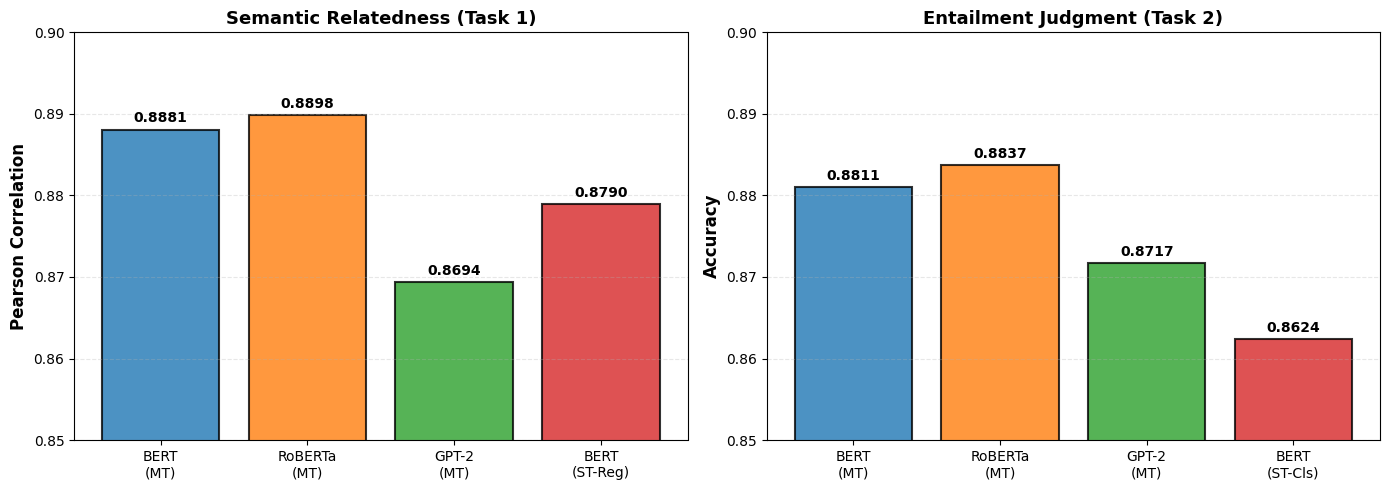

In [86]:
try:
    import matplotlib.pyplot as plt
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Pearson Correlation Comparison
    models = ['BERT\n(MT)', 'RoBERTa\n(MT)', 'GPT-2\n(MT)', 'BERT\n(ST-Reg)']
    pearson_scores = [test_pearson_corr, roberta_test_pearson, gpt2_test_pearson, st_regression_test_pearson]
    colors_pearson = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    
    axes[0].bar(models, pearson_scores, color=colors_pearson, alpha=0.8, edgecolor='black', linewidth=1.5)
    axes[0].set_ylabel('Pearson Correlation', fontsize=12, fontweight='bold')
    axes[0].set_title('Semantic Relatedness (Task 1)', fontsize=13, fontweight='bold')
    # 縮小 Y 軸範圍以突出差異
    axes[0].set_ylim([0.85, 0.90])
    axes[0].grid(axis='y', alpha=0.3, linestyle='--')
    
    # Add value labels on bars
    for i, v in enumerate(pearson_scores):
        axes[0].text(i, v + 0.0005, f'{v:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    
    # Accuracy Comparison
    models_acc = ['BERT\n(MT)', 'RoBERTa\n(MT)', 'GPT-2\n(MT)', 'BERT\n(ST-Cls)']
    accuracy_scores = [test_accuracy, roberta_test_accuracy, gpt2_test_accuracy, st_classification_test_accuracy]
    colors_acc = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']
    
    axes[1].bar(models_acc, accuracy_scores, color=colors_acc, alpha=0.8, edgecolor='black', linewidth=1.5)
    axes[1].set_ylabel('Accuracy', fontsize=12, fontweight='bold')
    axes[1].set_title('Entailment Judgment (Task 2)', fontsize=13, fontweight='bold')
    # 縮小 Y 軸範圍以突出差異
    axes[1].set_ylim([0.85, 0.90])
    axes[1].grid(axis='y', alpha=0.3, linestyle='--')
    
    # Add value labels on bars
    for i, v in enumerate(accuracy_scores):
        axes[1].text(i, v + 0.0005, f'{v:.4f}', ha='center', va='bottom', fontweight='bold', fontsize=10)
    
    plt.tight_layout()
    plt.savefig('images/model_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()
    
except ImportError:
    print("Matplotlib not installed. Visualizations skipped.")